<a href="https://colab.research.google.com/github/rakibhossainporosh/Ransomware-Attack-Prediction/blob/main/Ransomware_Attack.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
df = pd.read_csv('/content/drive/MyDrive/Data Set/data_file.csv')

In [3]:
print("Dataset loaded successfully.")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully.
Shape: (62485, 18)
Columns: ['FileName', 'md5Hash', 'Machine', 'DebugSize', 'DebugRVA', 'MajorImageVersion', 'MajorOSVersion', 'ExportRVA', 'ExportSize', 'IatVRA', 'MajorLinkerVersion', 'MinorLinkerVersion', 'NumberOfSections', 'SizeOfStackReserve', 'DllCharacteristics', 'ResourceSize', 'BitcoinAddresses', 'Benign']


In [4]:
df.head()

df['Benign'].value_counts()

,count
Benign,
0,35367
1,27118


In [5]:
drop_cols = ['FileName', 'md5Hash']

In [11]:
df_numeric = df.drop(columns=drop_cols).select_dtypes(include=['int64', 'float64']).drop(columns=['Benign'])
df1 = df_numeric.join(df['Benign'])

In [12]:
print("df1 created successfully:")
print("df1 shape (Benign):", df1.shape)

df1 created successfully:
df1 shape (Benign): (62485, 16)


In [13]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

In [14]:
X = df1.drop(columns=['Benign'])
y = df1['Benign']

In [15]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [18]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}


 Decision Tree Metrics:
Accuracy : 0.9941585980635352
Precision: 0.9933616079660704
Recall   : 0.9931784660766961
F1 Score : 0.9932700285793307
Confusion Matrix:
 [[7037   36]
 [  37 5387]]

 KNN Metrics:
Accuracy : 0.9920780987436985
Precision: 0.9915082148790844
Recall   : 0.9902286135693216
F1 Score : 0.990868001106909
Confusion Matrix:
 [[7027   46]
 [  53 5371]]

 Random Forest Metrics:
Accuracy : 0.9964791549971993
Precision: 0.9966765140324964
Recall   : 0.9952064896755162
F1 Score : 0.9959409594095942
Confusion Matrix:
 [[7055   18]
 [  26 5398]]


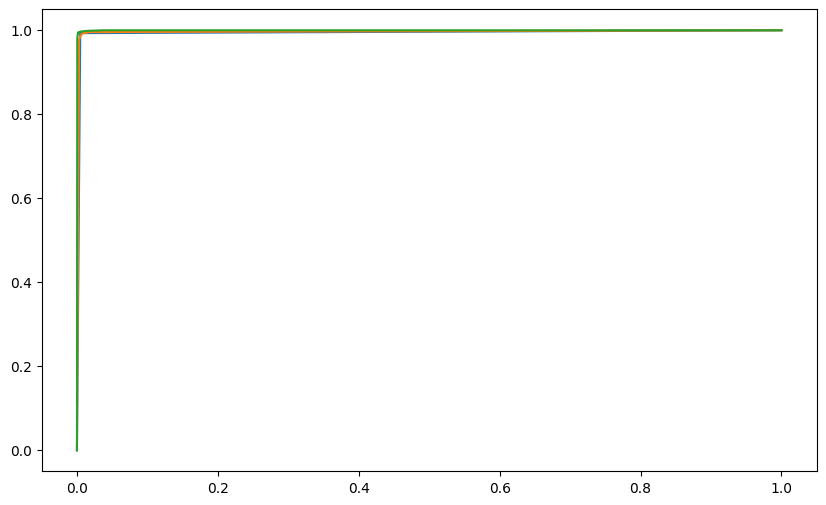

In [19]:
plt.figure(figsize=(10, 6))
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    print(f"\n {name} Metrics:")
    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall   :", recall_score(y_test, y_pred))
    print("F1 Score :", f1_score(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

/tmp/ipython-input-1921215464.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


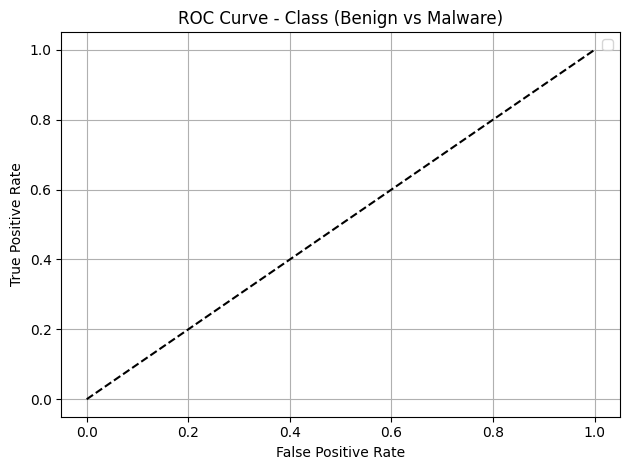

In [20]:
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Class (Benign vs Malware)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()